# BDD100K MOT Dataset Analysis

Multi-Object Tracking dataset from the BDD100K Kaggle dataset (robikscube).  
Source: `data/raw/bdd100k_mot/`

## 1. Setup & Paths

In [19]:
import sys
from pathlib import Path

# Find project root
ROOT = Path.cwd()
for _ in range(6):
    if (ROOT / "pyproject.toml").exists():
        break
    ROOT = ROOT.parent

print(f"Project root: {ROOT}")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

Project root: .


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2

DATA_DIR = ROOT / "data" / "raw" / "bdd100k_mot"
CSV_PATH = DATA_DIR / "mot_labels.csv"
PARQUET_PATH = DATA_DIR / "mot_labels.parquet"
VIDEO_DIR = DATA_DIR / "bdd100k_videos_train_00" / "bdd100k" / "videos" / "train"

print(f"CSV:       {CSV_PATH}")
print(f"Parquet:   {PARQUET_PATH}")
print(f"Video dir: {VIDEO_DIR}")

CSV:       data/raw/bdd100k_mot/mot_labels.csv
Parquet:   data/raw/bdd100k_mot/mot_labels.parquet
Video dir: data/raw/bdd100k_mot/bdd100k_videos_train_00/bdd100k/videos/train


In [21]:
df_all = pd.read_csv(CSV_PATH, low_memory=False)
print(f"Total rows: {len(df_all):,}")
print(f"Columns: {list(df_all.columns)}")

first_video = df_all["videoName"].iloc[0]
df_first = df_all[df_all["videoName"] == first_video]
print(f"\nFirst videoName: {first_video}  ({len(df_first):,} rows)")

car_id  = df_first[df_first["category"] == "car"]["id"].iloc[0]
ped_id  = df_first[df_first["category"] == "pedestrian"]["id"].iloc[0]
print(f"car id: {car_id},  pedestrian id: {ped_id}")

# Display sample rows for the car
print("\nSample rows for the car:")
df_sample_car = df_first[df_first["id"] == car_id]
print(df_sample_car.shape)
display(df_sample_car)

print("\nSample rows for the pedestrian:")
df_sample_ped = df_first[df_first["id"] == ped_id]
print(df_sample_ped.shape)
display(df_sample_ped)

Total rows: 2,890,846
Columns: ['name', 'videoName', 'frameIndex', 'id', 'category', 'attributes.crowd', 'attributes.occluded', 'attributes.truncated', 'box2d.x1', 'box2d.x2', 'box2d.y1', 'box2d.y2', 'haveVideo']

First videoName: 01c71072-718028b8  (3,326 rows)
car id: 89537.0,  pedestrian id: 89539.0

Sample rows for the car:
(89, 13)


,name,videoName,frameIndex,id,category,attributes.crowd,attributes.occluded,attributes.truncated,box2d.x1,box2d.x2,box2d.y1,box2d.y2,haveVideo
0,01c71072-718028b8-0000001.jpg,01c71072-718028b8,0,89537.0,car,False,True,False,825.173210,1003.094688,355.011547,418.198614,True
9,01c71072-718028b8-0000002.jpg,01c71072-718028b8,1,89537.0,car,False,True,False,836.812933,1014.734411,355.011547,418.198614,True
18,01c71072-718028b8-0000003.jpg,01c71072-718028b8,2,89537.0,car,False,True,False,874.226328,1070.438799,350.854503,417.367206,True
29,01c71072-718028b8-0000004.jpg,01c71072-718028b8,3,89537.0,car,False,True,False,941.570439,1145.265589,348.360277,418.198614,True
41,01c71072-718028b8-0000005.jpg,01c71072-718028b8,4,89537.0,car,False,True,False,983.972286,1187.667436,346.697460,416.535797,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2033,01c71072-718028b8-0000141.jpg,01c71072-718028b8,140,89537.0,car,False,False,False,721.247113,739.538106,314.272517,326.743649,True
2057,01c71072-718028b8-0000142.jpg,01c71072-718028b8,141,89537.0,car,False,False,False,724.572748,742.032333,315.103926,328.406467,True
2081,01c71072-718028b8-0000143.jpg,01c71072-718028b8,142,89537.0,car,False,False,False,727.898383,742.032333,315.103926,328.406467,True
2104,01c71072-718028b8-0000144.jpg,01c71072-718028b8,143,89537.0,car,False,False,False,729.561201,742.032333,315.103926,327.575058,True



Sample rows for the pedestrian:
(12, 13)


,name,videoName,frameIndex,id,category,attributes.crowd,attributes.occluded,attributes.truncated,box2d.x1,box2d.x2,box2d.y1,box2d.y2,haveVideo
2,01c71072-718028b8-0000001.jpg,01c71072-718028b8,0,89539.0,pedestrian,False,True,False,645.588915,663.879908,338.383372,358.337182,True
11,01c71072-718028b8-0000002.jpg,01c71072-718028b8,1,89539.0,pedestrian,False,True,False,653.071594,670.531178,338.383372,357.505774,True
20,01c71072-718028b8-0000003.jpg,01c71072-718028b8,2,89539.0,pedestrian,False,True,False,694.642032,714.595843,334.226328,359.168591,True
32,01c71072-718028b8-0000004.jpg,01c71072-718028b8,3,89539.0,pedestrian,False,True,False,753.672055,773.625866,329.237875,380.785219,True
44,01c71072-718028b8-0000005.jpg,01c71072-718028b8,4,89539.0,pedestrian,False,True,False,821.847575,838.475751,321.755196,357.505774,True
57,01c71072-718028b8-0000006.jpg,01c71072-718028b8,5,89539.0,pedestrian,False,True,False,877.551963,894.180139,320.923788,356.674365,True
69,01c71072-718028b8-0000007.jpg,01c71072-718028b8,6,89539.0,pedestrian,False,True,False,940.739030,964.849885,318.429561,364.988453,True
81,01c71072-718028b8-0000008.jpg,01c71072-718028b8,7,89539.0,pedestrian,False,True,False,999.769053,1034.688222,312.609700,384.110855,True
94,01c71072-718028b8-0000009.jpg,01c71072-718028b8,8,89539.0,pedestrian,False,True,False,1066.281755,1096.212471,315.103926,386.605081,True
107,01c71072-718028b8-0000010.jpg,01c71072-718028b8,9,89539.0,pedestrian,False,True,False,1129.468822,1158.568129,315.935335,378.290993,True


In [22]:
# Filter to videos that actually exist
df = df_all[df_all["haveVideo"] == True].copy()
print(f"Rows after haveVideo filter: {len(df):,}")
print(f"Unique videos: {df['videoName'].nunique()}")

Rows after haveVideo filter: 1,922,517
Unique videos: 961


## 2. Video Inventory

In [23]:
n_videos = df["videoName"].nunique()
n_frames = df.groupby("videoName")["frameIndex"].nunique().sum()
n_annotations = len(df)

print(f"Videos with annotations: {n_videos}")
print(f"Total annotated frames:  {n_frames:,}")
print(f"Total annotations:       {n_annotations:,}")
print(f"Avg annotations/frame:   {n_annotations/n_frames:.1f}")

Videos with annotations: 961
Total annotated frames:  190,469
Total annotations:       1,922,517
Avg annotations/frame:   10.1


In [24]:
# Annotations per video (top 10)
per_video = df.groupby("videoName").size().sort_values(ascending=False)
print("Top 10 videos by annotation count:")
print(per_video.head(10).to_string())

Top 10 videos by annotation count:
videoName
026c7465-309f6d33    5171
02645e20-f0955341    5143
000f8d37-d4c09a0f    5085
01e0535c-fe710ab9    5079
00abd8a7-ecd6fc56    4888
0245bba2-e3e6e1c0    4816
02097021-295d2161    4753
013ae324-9d336f91    4742
026e1e49-771df1d9    4718
002d290d-90f2bab2    4692


## 3. Category Distribution

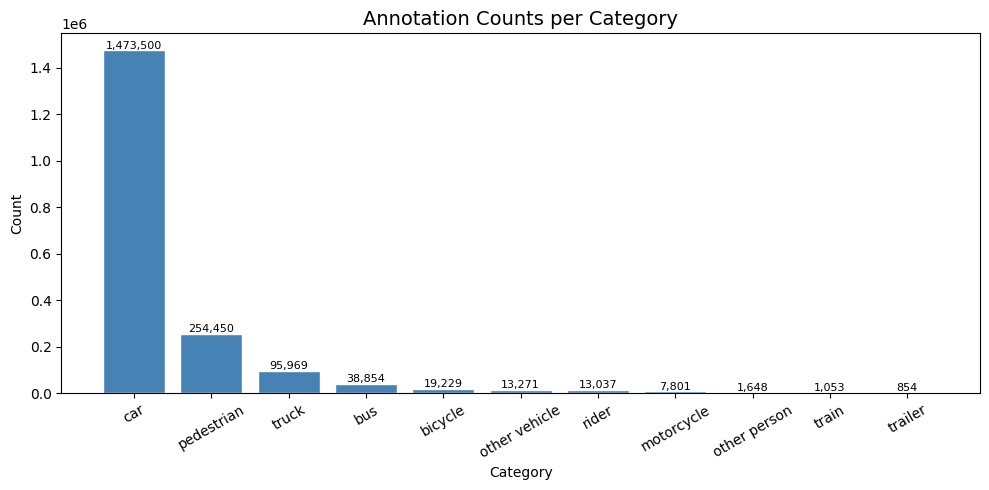

In [25]:
cat_counts = df["category"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(cat_counts.index, cat_counts.values, color="steelblue", edgecolor="white")
ax.set_title("Annotation Counts per Category", fontsize=14)
ax.set_xlabel("Category")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=30)

for i, v in enumerate(cat_counts.values):
    ax.text(i, v + cat_counts.max() * 0.005, f"{v:,}", ha="center", fontsize=8)

plt.tight_layout()
plt.show()

## 4. Frames per Video Distribution

Frames per video — min: 102, max: 263, mean: 198.2


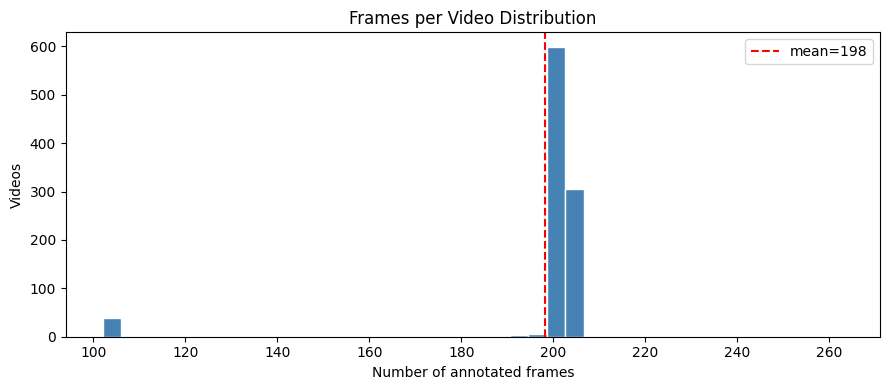

In [26]:
frames_per_video = df.groupby("videoName")["frameIndex"].nunique()

print(f"Frames per video — min: {frames_per_video.min()}, "
      f"max: {frames_per_video.max()}, "
      f"mean: {frames_per_video.mean():.1f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(frames_per_video, bins=40, color="steelblue", edgecolor="white")
ax.axvline(frames_per_video.mean(), color="red", linestyle="--", label=f"mean={frames_per_video.mean():.0f}")
ax.set_title("Frames per Video Distribution")
ax.set_xlabel("Number of annotated frames")
ax.set_ylabel("Videos")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Track Statistics

Tracks per video — min: 10, max: 378, mean: 79.0


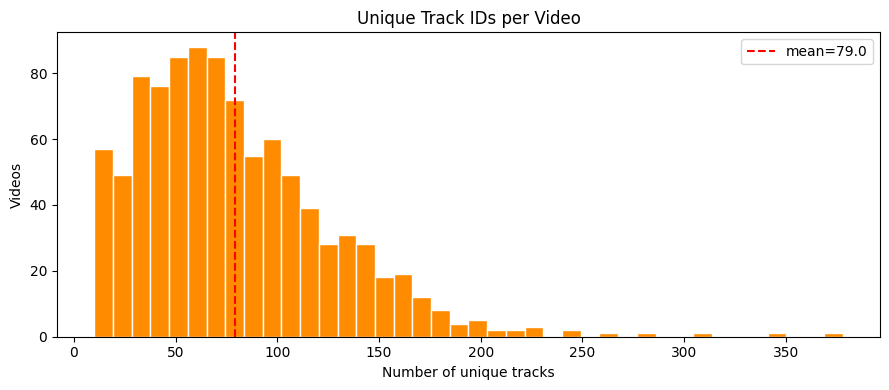

In [27]:
# Unique track IDs per video
tracks_per_video = df.groupby("videoName")["id"].nunique()
print(f"Tracks per video — min: {tracks_per_video.min()}, "
      f"max: {tracks_per_video.max()}, "
      f"mean: {tracks_per_video.mean():.1f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(tracks_per_video, bins=40, color="darkorange", edgecolor="white")
ax.axvline(tracks_per_video.mean(), color="red", linestyle="--",
           label=f"mean={tracks_per_video.mean():.1f}")
ax.set_title("Unique Track IDs per Video")
ax.set_xlabel("Number of unique tracks")
ax.set_ylabel("Videos")
ax.legend()
plt.tight_layout()
plt.show()

Track length — min: 1, max: 263, mean: 25.3, median: 15


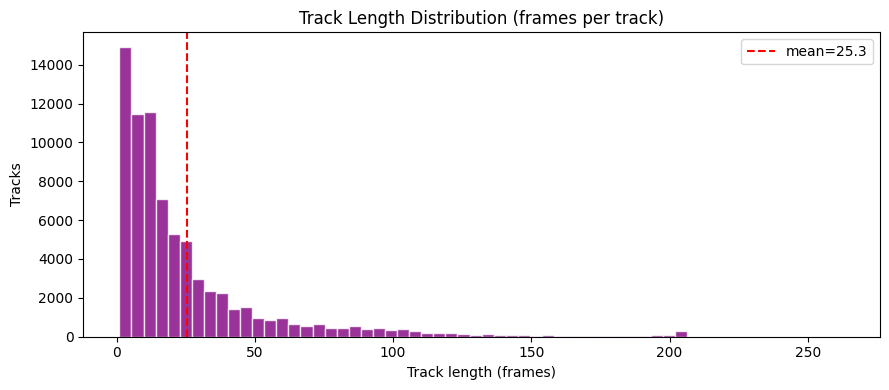

In [28]:
# Track length distribution (frames per track per video)
track_lengths = df.groupby(["videoName", "id"]).size()
print(f"Track length — min: {track_lengths.min()}, "
      f"max: {track_lengths.max()}, "
      f"mean: {track_lengths.mean():.1f}, "
      f"median: {track_lengths.median():.0f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(track_lengths, bins=60, color="purple", edgecolor="white", alpha=0.8)
ax.axvline(track_lengths.mean(), color="red", linestyle="--",
           label=f"mean={track_lengths.mean():.1f}")
ax.set_title("Track Length Distribution (frames per track)")
ax.set_xlabel("Track length (frames)")
ax.set_ylabel("Tracks")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Frame Visualization — 3 Videos × 4 Frames

In [29]:
CLASS_COLORS = {
    "pedestrian":    "#d62728",
    "car":           "#1f77b4",
    "bicycle":       "#9467bd",
    "motorcycle":    "#e377c2",
    "bus":           "#ff7f0e",
    "truck":         "#2ca02c",
    "rider":         "#8c564b",
}
DEFAULT_COLOR = "#7f7f7f"


def hex_to_rgb(hex_color):
    h = hex_color.lstrip("#")
    return tuple(int(h[i:i+2], 16) for i in (0, 2, 4))


def read_frame(video_path, frame_idx):
    """Read a single frame from a .mov file using cv2."""
    cap = cv2.VideoCapture(str(video_path))
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = cap.read()
    cap.release()
    if not ret:
        return None
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


def draw_overlay(frame_rgb, annots, alpha=0.3):
    """Col 1: image + semi-transparent filled bboxes + track IDs."""
    overlay = frame_rgb.copy()
    for _, row in annots.iterrows():
        color = hex_to_rgb(CLASS_COLORS.get(row["category"], DEFAULT_COLOR))
        x1, y1 = int(row["box2d.x1"]), int(row["box2d.y1"])
        x2, y2 = int(row["box2d.x2"]), int(row["box2d.y2"])
        cv2.rectangle(overlay, (x1, y1), (x2, y2), color, -1)
    blended = cv2.addWeighted(overlay, alpha, frame_rgb, 1 - alpha, 0)
    for _, row in annots.iterrows():
        color = hex_to_rgb(CLASS_COLORS.get(row["category"], DEFAULT_COLOR))
        x1, y1 = int(row["box2d.x1"]), int(row["box2d.y1"])
        cv2.putText(blended, f"ID:{int(row['id'])}", (x1, max(y1 - 4, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 1, cv2.LINE_AA)
    return blended


def draw_annotations_black(frame_rgb, annots):
    """Col 2: filled colored bboxes + 'ID:N category' labels on black background."""
    h, w = frame_rgb.shape[:2]
    canvas = np.zeros((h, w, 3), dtype=np.uint8)
    for _, row in annots.iterrows():
        color = hex_to_rgb(CLASS_COLORS.get(row["category"], DEFAULT_COLOR))
        x1, y1 = int(row["box2d.x1"]), int(row["box2d.y1"])
        x2, y2 = int(row["box2d.x2"]), int(row["box2d.y2"])
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, -1)
        cv2.putText(canvas, f"ID:{int(row['id'])} {row['category']}",
                    (x1, max(y1 - 4, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 1, cv2.LINE_AA)
    return canvas

In [30]:
# Pick 3 most-annotated videos
top3_videos = per_video.head(3).index.tolist()
print("Top 3 videos by annotation count:")
for v in top3_videos:
    print(f"  {v}: {per_video[v]:,} annotations")

Top 3 videos by annotation count:
  026c7465-309f6d33: 5,171 annotations
  02645e20-f0955341: 5,143 annotations
  000f8d37-d4c09a0f: 5,085 annotations


/tmp/ipykernel_147546/277967321.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


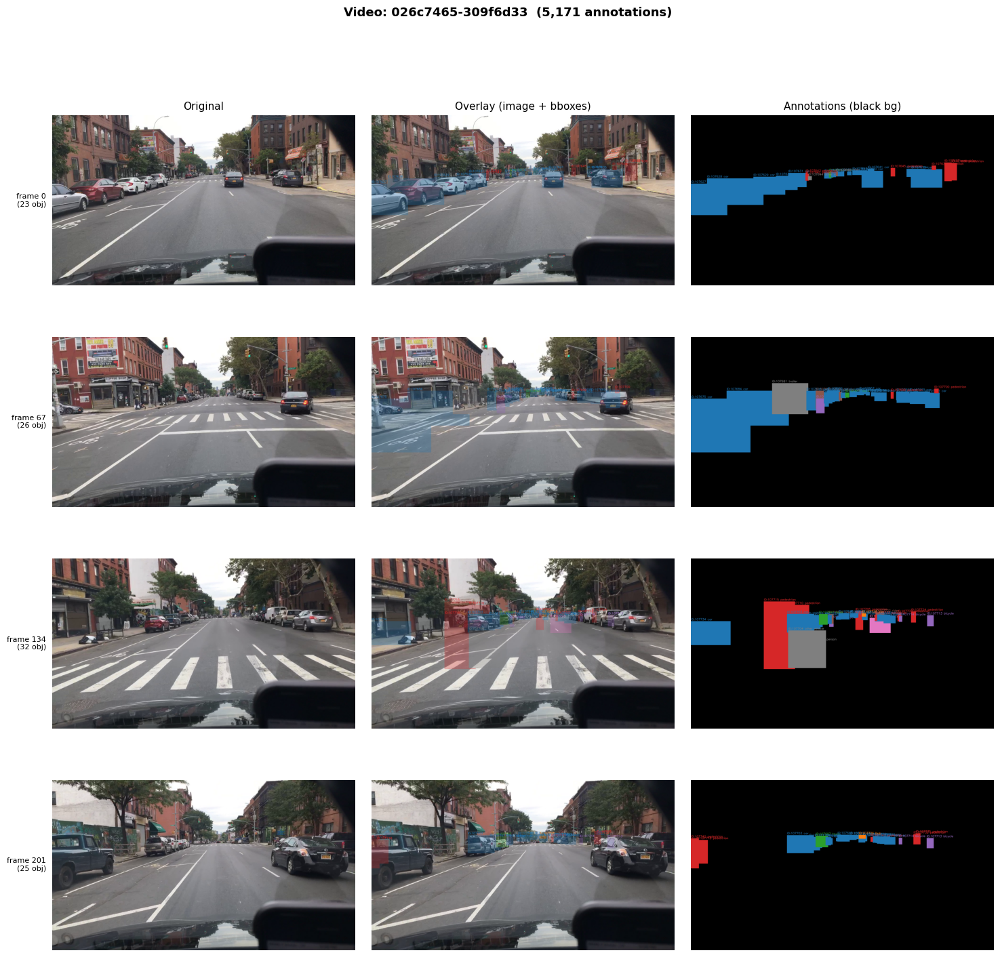

/tmp/ipykernel_147546/277967321.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


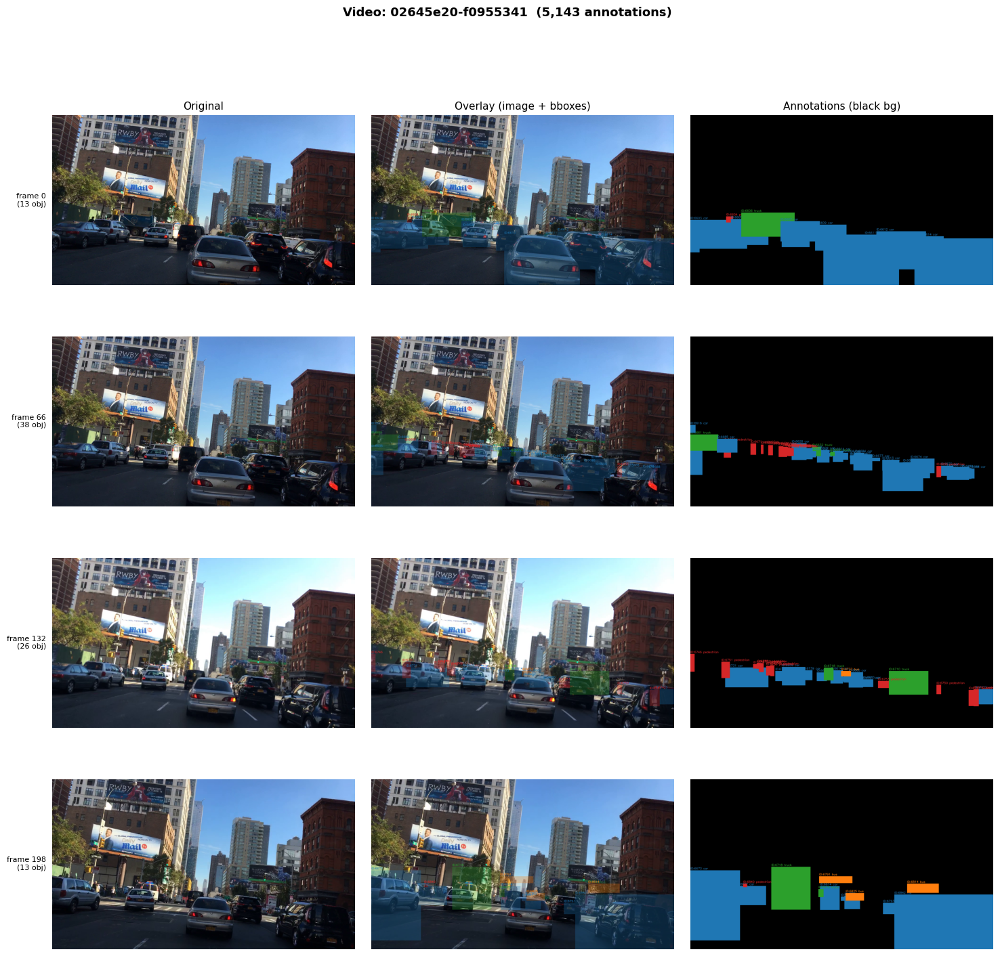

/tmp/ipykernel_147546/277967321.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


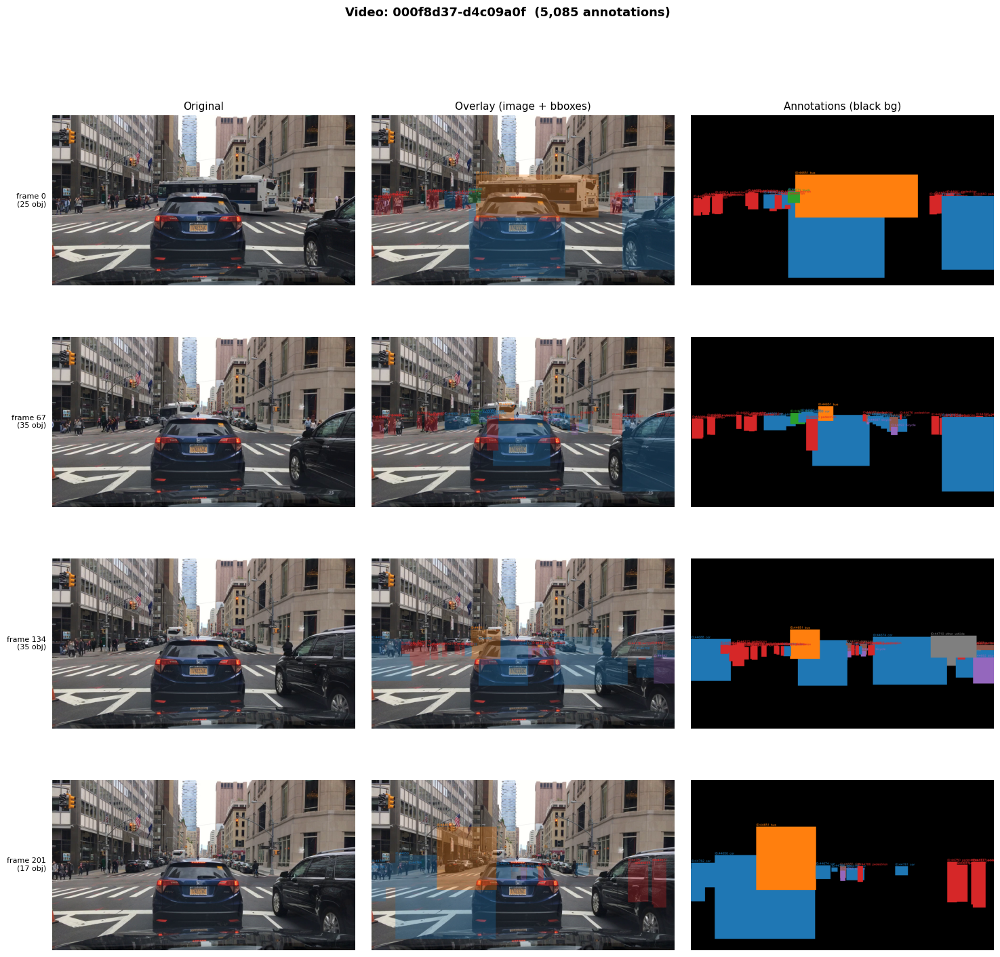

In [31]:
for video_name in top3_videos:
    video_path = VIDEO_DIR / f"{video_name}.mov"
    video_df   = df[df["videoName"] == video_name].copy()

    frame_indices = sorted(video_df["frameIndex"].unique())
    step   = max(1, (len(frame_indices) - 1) // 3)
    chosen = [frame_indices[i * step] for i in range(4)]

    fig, axes = plt.subplots(4, 3, figsize=(18, 16),
                              gridspec_kw={"hspace": 0.3, "wspace": 0.04})
    fig.suptitle(f"Video: {video_name}  ({per_video[video_name]:,} annotations)",
                 fontsize=13, fontweight="bold")

    col_titles = ["Original", "Overlay (image + bboxes)", "Annotations (black bg)"]
    for ax, title in zip(axes[0], col_titles):
        ax.set_title(title, fontsize=11)

    for row_idx, fidx in enumerate(chosen):
        frame_rgb = read_frame(video_path, int(fidx))
        annots    = video_df[video_df["frameIndex"] == fidx]

        if frame_rgb is None:
            for col_idx in range(3):
                axes[row_idx][col_idx].axis("off")
                axes[row_idx][col_idx].text(0.5, 0.5, "frame unavailable",
                                             ha="center", va="center",
                                             transform=axes[row_idx][col_idx].transAxes)
            continue

        imgs = [frame_rgb, draw_overlay(frame_rgb, annots), draw_annotations_black(frame_rgb, annots)]
        for col_idx, img in enumerate(imgs):
            axes[row_idx][col_idx].imshow(img)
            axes[row_idx][col_idx].axis("off")
        axes[row_idx][0].text(-0.02, 0.5, f"frame {fidx}\n({len(annots)} obj)",
                               va="center", ha="right", fontsize=8,
                               transform=axes[row_idx][0].transAxes)

    plt.tight_layout()
    plt.show()

### Diagnosis: FPS & Frame Alignment

The original `read_frame` seeks directly to `frameIndex` as if it were a raw video frame number.
This is only correct when the video's native FPS equals the annotation FPS (~5 Hz).
If the container stores frames at a higher rate the seek is off by a factor of `video_fps / annot_fps`.

In [32]:
# Check one video to measure actual container FPS vs annotation cadence
sample_video = top3_videos[0]
cap = cv2.VideoCapture(str(VIDEO_DIR / f"{sample_video}.mov"))
video_fps        = cap.get(cv2.CAP_PROP_FPS)
total_vid_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()

sample_vdf  = df[df["videoName"] == sample_video]
n_annot     = sample_vdf["frameIndex"].nunique()
max_fidx    = int(sample_vdf["frameIndex"].max())
duration_s  = total_vid_frames / video_fps if video_fps > 0 else 0
annot_fps   = n_annot / duration_s if duration_s > 0 else 0
stride      = total_vid_frames / n_annot if n_annot > 0 else 1.0

print(f"Video FPS (container):    {video_fps:.3f}")
print(f"Total video frames:       {total_vid_frames}")
print(f"Duration:                 {duration_s:.1f} s")
print(f"Annotated frames:         {n_annot}")
print(f"Max frameIndex:           {max_fidx}")
print(f"Estimated annotation FPS: {annot_fps:.2f} Hz")
print(f"Computed stride:          {stride:.3f}  (video frames per annotation)")
print()
if abs(stride - 1.0) < 0.1:
    print("✓ Stride ≈ 1 — direct frame seeking is correct.")
else:
    print(f"✗ Stride = {stride:.1f} — seeking directly to frameIndex is off by {stride:.1f}×!")
    print(f"  Fix: seek to round(frameIndex × {stride:.2f}) instead of frameIndex.")

Video FPS (container):    30.090
Total video frames:       1204
Duration:                 40.0 s
Annotated frames:         202
Max frameIndex:           201
Estimated annotation FPS: 5.05 Hz
Computed stride:          5.960  (video frames per annotation)

✗ Stride = 6.0 — seeking directly to frameIndex is off by 6.0×!
  Fix: seek to round(frameIndex × 5.96) instead of frameIndex.


### Fixed Visualization: 3 Videos × First 10 Annotated Frames

Uses `stride = total_video_frames / n_annotated_frames` so each seek lands on the correct video frame regardless of container FPS.

/tmp/ipykernel_147546/3530153040.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


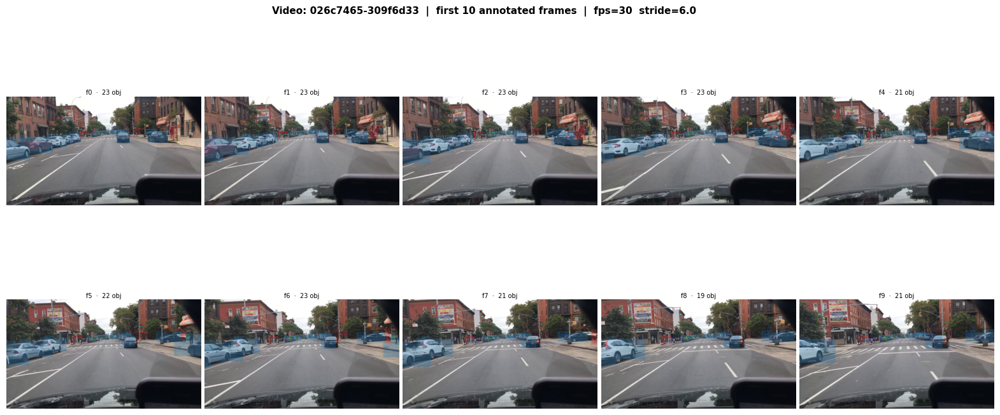

/tmp/ipykernel_147546/3530153040.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


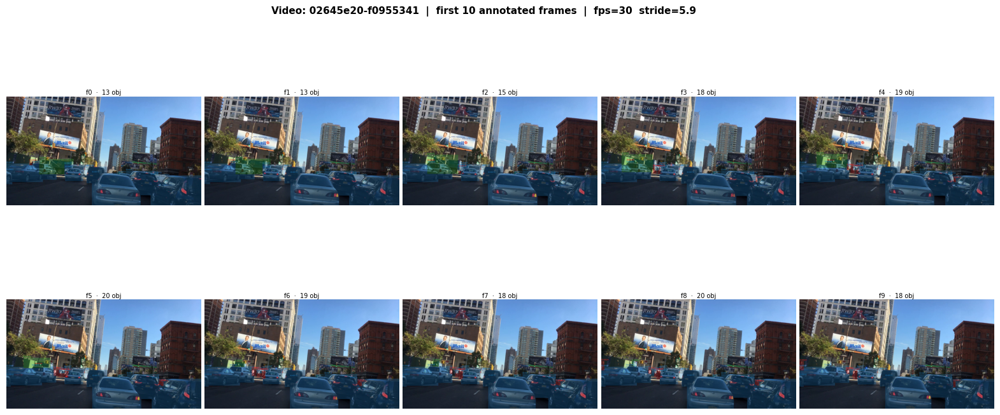

/tmp/ipykernel_147546/3530153040.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


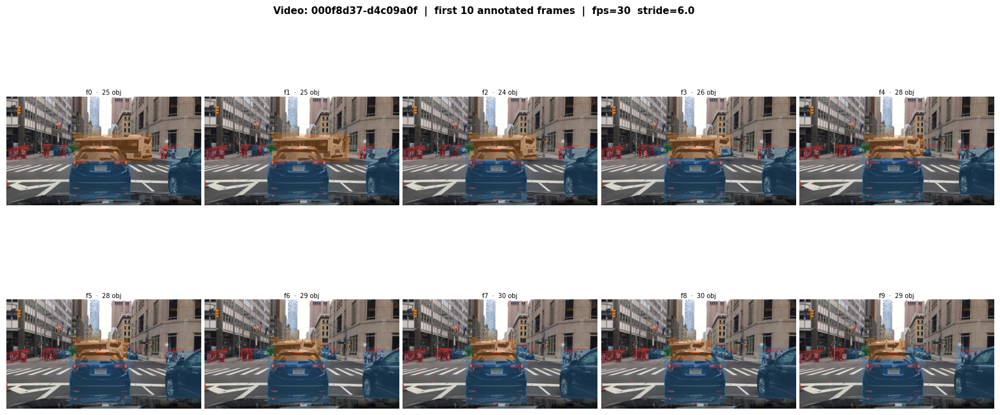

In [33]:
def read_frame_fixed(video_path: Path, frame_idx: int, stride: float):
    """Seek to the correct video frame for a given annotation frameIndex.

    stride = total_video_frames / n_annotated_frames
    (e.g. 6.0 when the container is at 30 fps but annotations are at 5 fps)
    """
    vid_frame_no = round(frame_idx * stride)
    cap = cv2.VideoCapture(str(video_path))
    cap.set(cv2.CAP_PROP_POS_FRAMES, vid_frame_no)
    ret, frame = cap.read()
    cap.release()
    if not ret:
        return None
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


N_FRAMES = 10
N_COLS   = 5
N_ROWS   = N_FRAMES // N_COLS  # 2

for video_name in top3_videos:
    video_path = VIDEO_DIR / f"{video_name}.mov"
    video_df   = df[df["videoName"] == video_name].copy()

    # Per-video stride
    cap = cv2.VideoCapture(str(video_path))
    vid_fps_v = cap.get(cv2.CAP_PROP_FPS)
    total_v   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    n_ann      = video_df["frameIndex"].nunique()
    vid_stride = total_v / n_ann

    frame_indices = sorted(video_df["frameIndex"].unique())[:N_FRAMES]

    fig, axes = plt.subplots(
        N_ROWS, N_COLS, figsize=(20, 8),
        gridspec_kw={"hspace": 0.08, "wspace": 0.02},
    )
    fig.suptitle(
        f"Video: {video_name}  |  first {N_FRAMES} annotated frames  "
        f"|  fps={vid_fps_v:.0f}  stride={vid_stride:.1f}",
        fontsize=11, fontweight="bold",
    )

    for i, fidx in enumerate(frame_indices):
        r, c = divmod(i, N_COLS)
        ax = axes[r][c]
        annots    = video_df[video_df["frameIndex"] == fidx]
        frame_rgb = read_frame_fixed(video_path, int(fidx), vid_stride)

        if frame_rgb is None:
            ax.axis("off")
            ax.text(0.5, 0.5, "unavailable", ha="center", va="center",
                    transform=ax.transAxes, fontsize=8)
            continue

        ax.imshow(draw_overlay(frame_rgb, annots))
        ax.axis("off")
        ax.set_title(f"f{fidx}  ·  {len(annots)} obj", fontsize=7, pad=2)

    plt.tight_layout()
    plt.show()

### Frame-count Analysis: Video Frames vs Annotated Frames

`CAP_PROP_POS_FRAMES` is unreliable for H.264 `.mov` on Linux — it snaps to key-frames, not the exact position.
The correct approach is **sequential read**: advance through every raw video frame, pick the ones whose
position matches `round(ann_idx × stride)`.  This cell shows the per-video counts and stride to understand the mismatch.

### Video Export — Sequential Read

Reads every raw video frame in order (no seeking).  
Pre-computes `{video_frame_num → annotation_idx}` via `round(ann_idx × stride)`, writes only matched frames at annotation FPS.  
Output: `outputs/mot_video_overlays/{video_name}_annotated.mp4`

In [34]:
OUT_DIR = ROOT / "outputs" / "mot_video_overlays"
OUT_DIR.mkdir(parents=True, exist_ok=True)


def export_annotated_video(video_name: str, video_path: Path, video_df, out_dir: Path) -> dict:
    """Export an annotated MP4 by reading every video frame sequentially.

    Avoids CAP_PROP_POS_FRAMES seeking (unreliable for H.264 .mov on Linux).
    Pre-computes {video_frame_num -> annotation_idx} and writes only the matched
    frames, so every output frame has ground-truth boxes.
    """
    cap     = cv2.VideoCapture(str(video_path))
    vid_fps = cap.get(cv2.CAP_PROP_FPS)
    n_vid   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    w       = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h       = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    n_ann   = video_df["frameIndex"].nunique()
    stride  = n_vid / n_ann

    # Map: video frame number -> annotation frameIndex
    keep: dict[int, int] = {
        round(ann_idx * stride): ann_idx
        for ann_idx in sorted(video_df["frameIndex"].unique())
    }

    out_path     = out_dir / f"{video_name}_annotated.mp4"
    ann_fps_out  = vid_fps / stride                   # ~5 fps
    fourcc       = cv2.VideoWriter_fourcc(*"mp4v")
    out          = cv2.VideoWriter(str(out_path), fourcc, ann_fps_out, (w, h))

    frame_num = 0
    n_written = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if frame_num in keep:
            ann_idx = keep[frame_num]
            annots  = video_df[video_df["frameIndex"] == ann_idx]

            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            overlay   = draw_overlay(frame_rgb, annots)
            frame_out = cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)

            label = (f"annot {ann_idx}/{n_ann - 1}"
                     f"  vid {frame_num}/{n_vid - 1}"
                     f"  {len(annots)} obj")
            cv2.putText(frame_out, label, (8, 24),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2, cv2.LINE_AA)
            cv2.putText(frame_out, label, (8, 24),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 1, cv2.LINE_AA)
            out.write(frame_out)
            n_written += 1
        frame_num += 1

    cap.release()
    out.release()

    return {
        "video":         video_name,
        "vid_fps":       vid_fps,
        "n_vid_frames":  n_vid,
        "n_ann_frames":  n_ann,
        "stride":        round(stride, 3),
        "out_fps":       round(ann_fps_out, 2),
        "n_written":     n_written,
        "output":        str(out_path),
    }


for video_name in top3_videos:
    info = export_annotated_video(
        video_name,
        VIDEO_DIR / f"{video_name}.mov",
        df[df["videoName"] == video_name].copy(),
        OUT_DIR,
    )
    print(f"✓  {info['video']}")
    print(f"   container : {info['n_vid_frames']} frames @ {info['vid_fps']:.1f} fps")
    print(f"   annotated : {info['n_ann_frames']} frames  stride={info['stride']}  out_fps={info['out_fps']}")
    print(f"   written   : {info['n_written']} frames  →  {info['output']}")
    print()

✓  026c7465-309f6d33
   container : 1204 frames @ 30.1 fps
   annotated : 202 frames  stride=5.96  out_fps=5.05
   written   : 202 frames  →  outputs/mot_video_overlays/026c7465-309f6d33_annotated.mp4

✓  02645e20-f0955341
   container : 1184 frames @ 29.7 fps
   annotated : 200 frames  stride=5.92  out_fps=5.02
   written   : 200 frames  →  outputs/mot_video_overlays/02645e20-f0955341_annotated.mp4

✓  000f8d37-d4c09a0f
   container : 1210 frames @ 30.1 fps
   annotated : 202 frames  stride=5.99  out_fps=5.03
   written   : 202 frames  →  outputs/mot_video_overlays/000f8d37-d4c09a0f_annotated.mp4



,video,container_fps,total_vid_frames,n_annotated,stride,ann_fps_est,duration_s
0,026c7465-309f6d33,30.09,1204,202,5.96,5.05,40.0
1,02645e20-f0955341,29.75,1184,200,5.92,5.02,39.8
2,000f8d37-d4c09a0f,30.15,1210,202,5.99,5.03,40.1


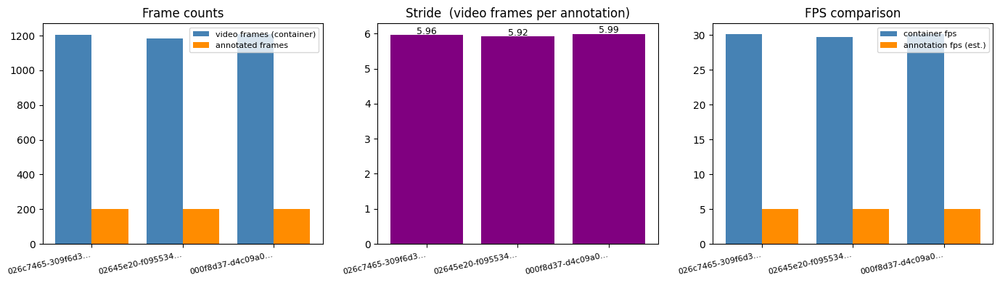

In [35]:
# Per-video: container frames vs annotated frames vs stride
rows = []
for video_name in top3_videos:
    cap      = cv2.VideoCapture(str(VIDEO_DIR / f"{video_name}.mov"))
    vid_fps  = cap.get(cv2.CAP_PROP_FPS)
    n_vid    = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()

    n_ann      = df[df["videoName"] == video_name]["frameIndex"].nunique()
    stride     = n_vid / n_ann if n_ann > 0 else 0
    duration_s = n_vid / vid_fps if vid_fps > 0 else 0
    ann_fps    = n_ann / duration_s if duration_s > 0 else 0

    rows.append({
        "video":             video_name,
        "container_fps":     round(vid_fps, 2),
        "total_vid_frames":  n_vid,
        "n_annotated":       n_ann,
        "stride":            round(stride, 3),
        "ann_fps_est":       round(ann_fps, 2),
        "duration_s":        round(duration_s, 1),
    })

summary = pd.DataFrame(rows)
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

labels = [v[:16] + "…" for v in top3_videos]
x      = range(len(top3_videos))

# 1) Frame counts side by side
axes[0].bar([i - 0.2 for i in x], summary["total_vid_frames"], width=0.4,
            label="video frames (container)", color="steelblue")
axes[0].bar([i + 0.2 for i in x], summary["n_annotated"], width=0.4,
            label="annotated frames", color="darkorange")
axes[0].set_xticks(list(x)); axes[0].set_xticklabels(labels, rotation=12, ha="right", fontsize=8)
axes[0].set_title("Frame counts"); axes[0].legend(fontsize=8)

# 2) Stride
axes[1].bar(list(x), summary["stride"], color="purple")
axes[1].set_xticks(list(x)); axes[1].set_xticklabels(labels, rotation=12, ha="right", fontsize=8)
axes[1].set_title("Stride  (video frames per annotation)")
for i, s in enumerate(summary["stride"]):
    axes[1].text(i, s + 0.03, f"{s:.2f}", ha="center", fontsize=9)

# 3) FPS comparison
axes[2].bar([i - 0.2 for i in x], summary["container_fps"], width=0.4,
            label="container fps", color="steelblue")
axes[2].bar([i + 0.2 for i in x], summary["ann_fps_est"],   width=0.4,
            label="annotation fps (est.)", color="darkorange")
axes[2].set_xticks(list(x)); axes[2].set_xticklabels(labels, rotation=12, ha="right", fontsize=8)
axes[2].set_title("FPS comparison"); axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### First 10 Annotated Frames — Sequential Read (correct)

Reads every video frame in order; only keeps the ones whose raw position matches `round(ann_idx × stride)`.
No seeking — guaranteed to land on the right frame regardless of codec or key-frame spacing.

/tmp/ipykernel_147546/3335892319.py:60: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


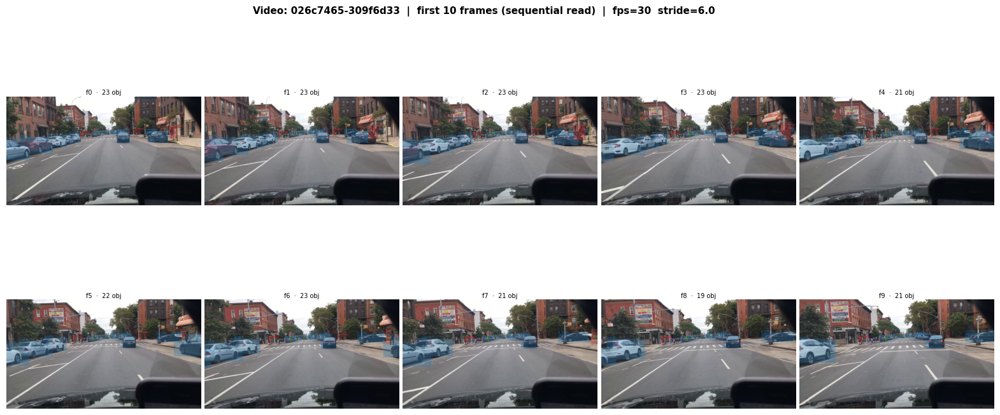

/tmp/ipykernel_147546/3335892319.py:60: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


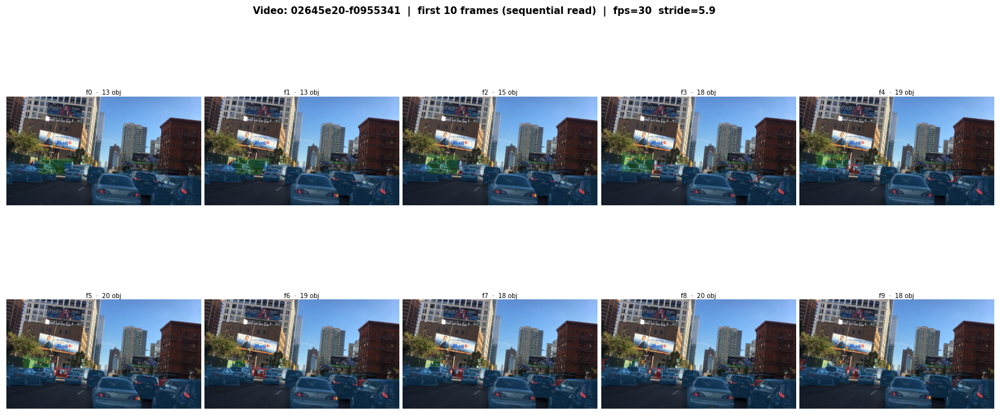

/tmp/ipykernel_147546/3335892319.py:60: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


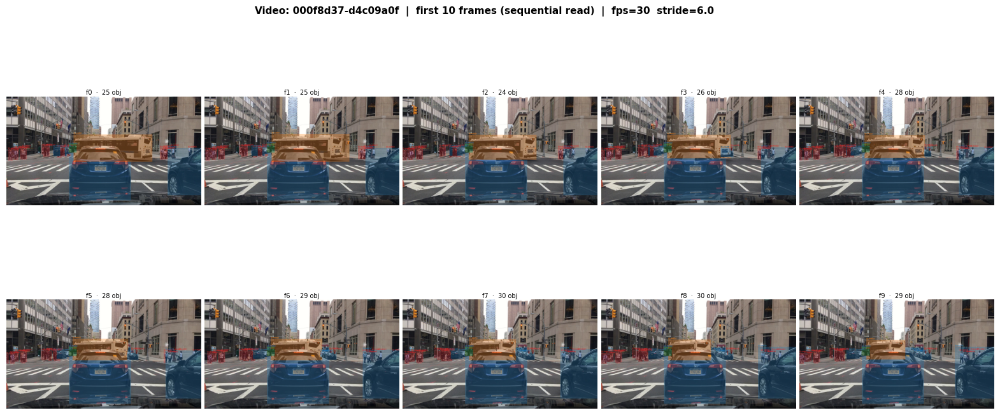

In [36]:
def collect_first_n_annotated(video_path: Path, video_df, n: int = 10):
    """Sequential read: collect first n annotated frames (no seeking)."""
    cap    = cv2.VideoCapture(str(video_path))
    n_vid  = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    n_ann  = video_df["frameIndex"].nunique()
    stride = n_vid / n_ann
    ann_indices = sorted(video_df["frameIndex"].unique())[:n]
    keep = {round(idx * stride): idx for idx in ann_indices}
    collected: dict = {}
    frame_num = 0
    max_target = max(keep)
    while frame_num <= max_target:
        ret, frame = cap.read()
        if not ret:
            break
        if frame_num in keep:
            collected[keep[frame_num]] = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame_num += 1
    cap.release()
    return collected, stride


N_FRAMES, N_COLS, N_ROWS = 10, 5, 2

for video_name in top3_videos:
    video_path = VIDEO_DIR / f"{video_name}.mov"
    video_df   = df[df["videoName"] == video_name].copy()

    collected, stride = collect_first_n_annotated(video_path, video_df, N_FRAMES)

    cap = cv2.VideoCapture(str(video_path))
    vid_fps = cap.get(cv2.CAP_PROP_FPS)
    n_vid   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()

    fig, axes = plt.subplots(
        N_ROWS, N_COLS, figsize=(20, 8),
        gridspec_kw={"hspace": 0.08, "wspace": 0.02},
    )
    fig.suptitle(
        f"Video: {video_name}  |  first {N_FRAMES} frames (sequential read)  |  "
        f"fps={vid_fps:.0f}  stride={stride:.1f}",
        fontsize=11, fontweight="bold",
    )

    for i, ann_idx in enumerate(sorted(collected.keys())):
        r, c = divmod(i, N_COLS)
        ax = axes[r][c]
        frame_rgb = collected[ann_idx]
        annots    = video_df[video_df["frameIndex"] == ann_idx]
        ax.imshow(draw_overlay(frame_rgb, annots))
        ax.axis("off")
        ax.set_title(f"f{ann_idx}  ·  {len(annots)} obj", fontsize=7, pad=2)

    # hide any leftover axes if collected < N_FRAMES
    for j in range(len(collected), N_ROWS * N_COLS):
        r, c = divmod(j, N_COLS)
        axes[r][c].axis("off")

    plt.tight_layout()
    plt.show()

### Video Export — Native FPS (annotations on matched frames only)

Exports each video at its original container FPS.  
- Annotated frames (those matching ) get bounding-box overlays drawn on them.  
- All other frames are written as-is (no boxes).

Output: 

In [40]:
OUT_DIR_NATIVE = ROOT / "outputs" / "mot_video_overlays_native"
OUT_DIR_NATIVE.mkdir(parents=True, exist_ok=True)


def export_native_fps_video(
    video_name: str, video_path: Path, video_df, out_dir: Path
) -> dict:
    """Export video at original FPS; draw boxes only on annotated matched frames."""
    cap     = cv2.VideoCapture(str(video_path))
    vid_fps = cap.get(cv2.CAP_PROP_FPS)
    n_vid   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    w       = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h       = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    n_ann  = video_df["frameIndex"].nunique()
    stride = n_vid / n_ann
    keep   = {round(idx * stride): idx for idx in video_df["frameIndex"].unique()}

    out_path = out_dir / f"{video_name}_native_fps.mp4"
    fourcc   = cv2.VideoWriter_fourcc(*"mp4v")
    out      = cv2.VideoWriter(str(out_path), fourcc, vid_fps, (w, h))

    frame_num   = 0
    n_annotated = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if frame_num in keep:
            ann_idx   = keep[frame_num]
            annots    = video_df[video_df["frameIndex"] == ann_idx]
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            overlay   = draw_overlay(frame_rgb, annots)
            frame_out = cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)
            label = (
                f"annot {ann_idx}/{n_ann - 1}  "                f"vid {frame_num}/{n_vid - 1}  "                f"{len(annots)} obj"
            )
            cv2.putText(frame_out, label, (8, 24), cv2.FONT_HERSHEY_SIMPLEX,
                        0.55, (255, 255, 255), 2, cv2.LINE_AA)
            cv2.putText(frame_out, label, (8, 24), cv2.FONT_HERSHEY_SIMPLEX,
                        0.55, (0, 0, 0), 1, cv2.LINE_AA)
            out.write(frame_out)
            n_annotated += 1
        else:
            out.write(frame)
        frame_num += 1

    cap.release()
    out.release()
    return {
        "video":        video_name,
        "vid_fps":      vid_fps,
        "n_vid_frames": n_vid,
        "n_ann_frames": n_ann,
        "stride":       round(stride, 3),
        "n_annotated":  n_annotated,
        "output":       str(out_path),
    }


for video_name in top3_videos:
    info = export_native_fps_video(
        video_name,
        VIDEO_DIR / f"{video_name}.mov",
        df[df["videoName"] == video_name].copy(),
        OUT_DIR_NATIVE,
    )
    print(f"✓  {info['video']}")
    print(f"   container : {info['n_vid_frames']} frames @ {info['vid_fps']:.1f} fps")
    print(f"   annotated : {info['n_ann_frames']} / {info['n_vid_frames']} frames have boxes  (stride={info['stride']})")
    print(f"   output    : {info['output']}")

✓  026c7465-309f6d33
   container : 1204 frames @ 30.1 fps
   annotated : 202 / 1204 frames have boxes  (stride=5.96)
   output    : outputs/mot_video_overlays_native/026c7465-309f6d33_native_fps.mp4
✓  02645e20-f0955341
   container : 1184 frames @ 29.7 fps
   annotated : 200 / 1184 frames have boxes  (stride=5.92)
   output    : outputs/mot_video_overlays_native/02645e20-f0955341_native_fps.mp4
✓  000f8d37-d4c09a0f
   container : 1210 frames @ 30.1 fps
   annotated : 202 / 1210 frames have boxes  (stride=5.99)
   output    : outputs/mot_video_overlays_native/000f8d37-d4c09a0f_native_fps.mp4


## 7. Track Continuity Visualization

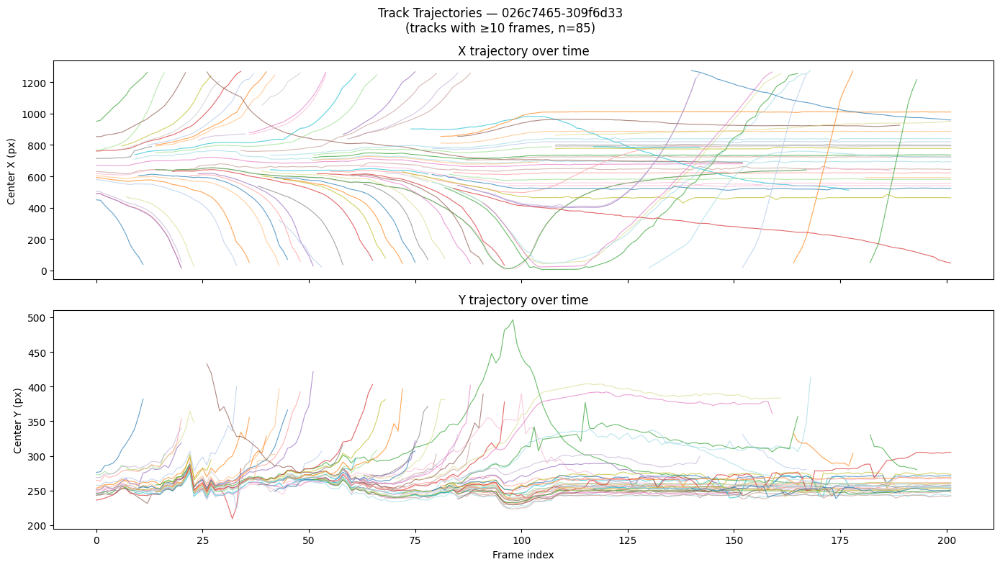

In [41]:
# Use the first of the top-3 videos
viz_video = top3_videos[0]
vdf = df[df["videoName"] == viz_video].copy()

# Compute bbox center
vdf["cx"] = (vdf["box2d.x1"] + vdf["box2d.x2"]) / 2
vdf["cy"] = (vdf["box2d.y1"] + vdf["box2d.y2"]) / 2

# Only show tracks with >= 10 frames for readability
track_len = vdf.groupby("id").size()
long_tracks = track_len[track_len >= 10].index
vdf_long = vdf[vdf["id"].isin(long_tracks)]

cmap = plt.cm.tab20
track_ids = vdf_long["id"].unique()
colors = {tid: cmap(i % 20) for i, tid in enumerate(track_ids)}

fig, (ax_x, ax_y) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fig.suptitle(f"Track Trajectories — {viz_video}\n(tracks with ≥10 frames, n={len(track_ids)})",
             fontsize=12)

for tid, grp in vdf_long.groupby("id"):
    grp_sorted = grp.sort_values("frameIndex")
    c = colors[tid]
    ax_x.plot(grp_sorted["frameIndex"], grp_sorted["cx"], color=c, linewidth=0.8, alpha=0.7)
    ax_y.plot(grp_sorted["frameIndex"], grp_sorted["cy"], color=c, linewidth=0.8, alpha=0.7)

ax_x.set_ylabel("Center X (px)")
ax_x.set_title("X trajectory over time")
ax_y.set_ylabel("Center Y (px)")
ax_y.set_xlabel("Frame index")
ax_y.set_title("Y trajectory over time")

plt.tight_layout()
plt.show()

## 8. Scene Attribute Limitation

The `mot_labels.csv` file contains only object-level annotations:

| Present | Absent |
|---|---|
| Bounding boxes (`box2d.*`) | Weather (clear / rainy / foggy …) |
| Category & track ID | Scene type (city / highway …) |
| Occlusion / truncation flags | Time of day (daytime / night …) |

Scene-level attributes (weather, time-of-day, scene type) are available in the full BDD100K annotation JSON files (`bdd100k_labels_images_train.json`), which are **not included** in this Kaggle split.  
For weather/scene stratified analysis, the full BDD100K dataset must be downloaded separately.